In [8]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


ORIGINAL DATASET
   Study_Hours  Concentration  Performance  Sleep_Quality  Energy_Level  \
0     5.972168       5.971371     7.255142       5.502691      4.974802   
1     4.515954       4.627665     6.176283       5.600198      5.831524   
2     6.232415       5.815675     6.930616       6.444656      6.665638   
3     7.691236       6.642726     7.873467       6.532932      6.446764   
4     4.772800       4.545217     5.951475       3.223688      3.882983   

   Physical_Activity  
0           3.013528  
1           4.830701  
2           4.747907  
3           4.736700  
4           4.266824  

FACTOR LOADINGS
                   Factor 1  Factor 2  Factor 3
Study_Hours          -0.977    -0.065     0.033
Concentration        -0.953    -0.082    -0.029
Performance          -0.950    -0.049    -0.039
Sleep_Quality        -0.124     0.951     0.065
Energy_Level         -0.122     0.950    -0.066
Physical_Activity     0.169    -0.010     0.423

LATENT FACTOR VALUES
   Factor 1  Factor

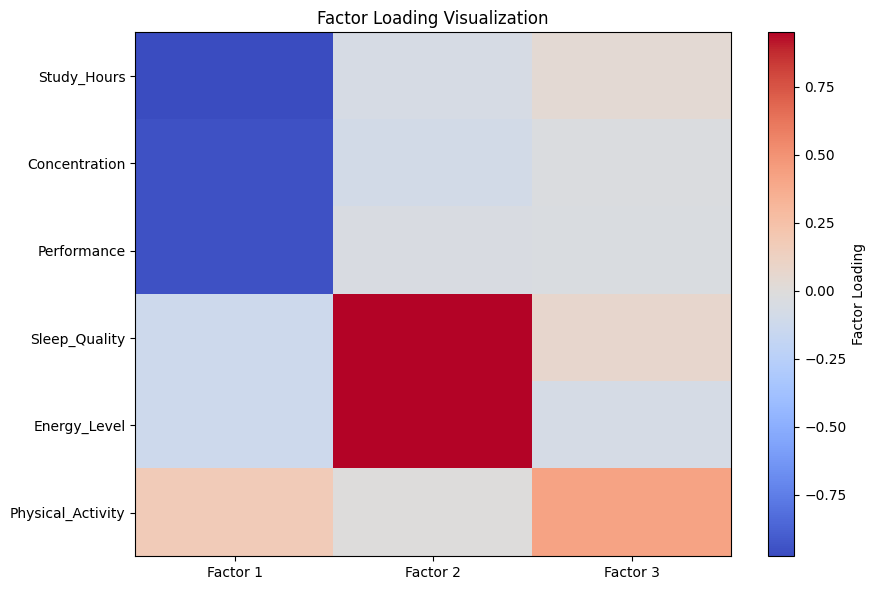

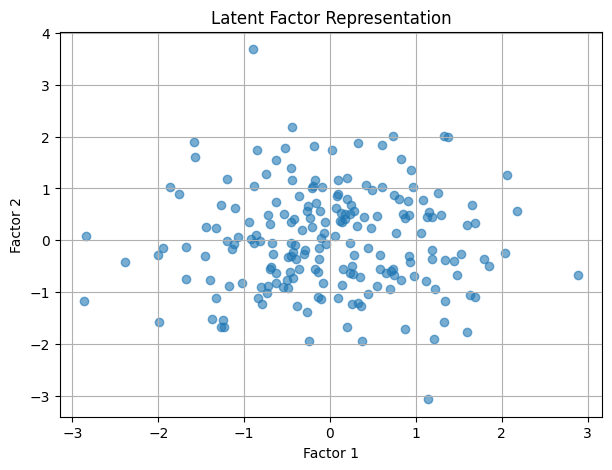


FACTOR CORRELATION
          Factor 1  Factor 2  Factor 3
Factor 1       1.0       0.0      -0.0
Factor 2       0.0       1.0      -0.0
Factor 3      -0.0      -0.0       1.0


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis

# 1. Generate sample dataset
np.random.seed(42)

n = 200

study = np.random.normal(size=n)
sleep = np.random.normal(size=n)
activity = np.random.normal(size=n)

data = pd.DataFrame({
    "Study_Hours": 5 + 1.5 * study + np.random.normal(0, 0.3, n),
    "Concentration": 5 + 1.2 * study + np.random.normal(0, 0.4, n),
    "Performance": 6 + 1.4 * study + np.random.normal(0, 0.4, n),
    "Sleep_Quality": 5 + 1.3 * sleep + np.random.normal(0, 0.3, n),
    "Energy_Level": 5 + 1.1 * sleep + np.random.normal(0, 0.4, n),
    "Physical_Activity": 5 + 1.2 * activity + np.random.normal(0, 0.4, n)
})

print("ORIGINAL DATASET")
print(data.head())

# 2. Standardize data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(data)

# 3. Apply Factor Analysis
fa = FactorAnalysis(
    n_components=3,
    random_state=42
)

X_factors = fa.fit_transform(X_scaled)

# 4. Display factor loadings
loadings = pd.DataFrame(
    fa.components_.T,
    index=data.columns,
    columns=["Factor 1", "Factor 2", "Factor 3"]
)

print("\nFACTOR LOADINGS")
print(loadings.round(3))

# 5. Display latent factors
factor_data = pd.DataFrame(
    X_factors,
    columns=["Factor 1", "Factor 2", "Factor 3"]
)

print("\nLATENT FACTOR VALUES")
print(factor_data.head())

# 6. Display noise variance
print("\nNOISE VARIANCE")
print(fa.noise_variance_)

# 7. Visualize factor loadings
plt.figure(figsize=(9, 6))

plt.imshow(
    loadings,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar(label="Factor Loading")

plt.xticks(range(3), loadings.columns)

plt.yticks(
    range(len(data.columns)),
    data.columns
)

plt.title("Factor Loading Visualization")

plt.tight_layout()
plt.show()

# 8. Visualize latent factors
plt.figure(figsize=(7, 5))

plt.scatter(
    X_factors[:, 0],
    X_factors[:, 1],
    alpha=0.6
)

plt.xlabel("Factor 1")
plt.ylabel("Factor 2")

plt.title("Latent Factor Representation")

plt.grid()
plt.show()

# 9. Display factor correlation
print("\nFACTOR CORRELATION")

print(
    factor_data.corr().round(3)
)